#### Importação das bibliotecas ####

In [97]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from datetime import datetime
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

#### Carregando o dataset ####

In [98]:
df = pd.read_csv("data/ecommerce.csv", encoding='latin1')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


#### Limpeza e tratamento de dados ####

In [99]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


Foram detectados ~145 mil valores faltantes na coluna 'CustomerID' e 1.454 na coluna 'Description'.

Não é possível preencher os valores faltantes da coluna 'CustomerID', visto que ela corresponde ao identificador do dono daquela transação, então não podemos estimar um valor para essas linhas.

Também não é possível preencher os valores nulos de 'Description', visto que é uma coluna em formato de texto.

Dito isso, podemos concluir que a melhor forma de tratamento desses dados é o drop dessas linhas.

In [100]:
df = df.dropna()

##### Verificando o dataset após o tratamento dos dados #####

In [101]:
df.info()

<class 'pandas.DataFrame'>
Index: 406829 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    406829 non-null  str    
 1   StockCode    406829 non-null  str    
 2   Description  406829 non-null  str    
 3   Quantity     406829 non-null  int64  
 4   InvoiceDate  406829 non-null  str    
 5   UnitPrice    406829 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      406829 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 27.9 MB


##### Verificando valores negativos #####

In [102]:
print(f'Transações com valor negativo: {(df['Quantity'] < 0).sum()}')

Transações com valor negativo: 8905


Transações com valor negativo correspondem aos reembolsos dos clientes.

Dropando as linhas que correspondem à uma devolução.

In [103]:
df = df[~(df['Quantity'] < 0)]

In [104]:
df.info()

<class 'pandas.DataFrame'>
Index: 397924 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    397924 non-null  str    
 1   StockCode    397924 non-null  str    
 2   Description  397924 non-null  str    
 3   Quantity     397924 non-null  int64  
 4   InvoiceDate  397924 non-null  str    
 5   UnitPrice    397924 non-null  float64
 6   CustomerID   397924 non-null  float64
 7   Country      397924 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 27.3 MB


#### Feature Engineering ####

Criando a coluna 'TotalPrice' que corresponde ao gasto total na compra, multiplicando a quantidade do produto comprado com o seu preço por unidade.

In [105]:
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

In [106]:
df[['Quantity', 'UnitPrice', 'TotalPrice']].head()

,Quantity,UnitPrice,TotalPrice
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


#### RFM ####

##### Monetary #####

Corresponde ao gasto total por cliente no dataset.

Vamos somar todos os gastos totais das transações por cliente.

In [107]:
monetary = df.groupby(by=['CustomerID'], as_index=False)[['TotalPrice']].sum()

##### Frequency #####

Corresponde a quantidade de transações feitas por cliente num determinado espaço de tempo.

Para isso vamos contar quantos valores distintos de 'InvoiceNo' possuem por cliente.

'InvoiceNo' corresponde ao número da transação.

In [108]:
frequency = df.groupby(by=['CustomerID'], as_index=False)[['InvoiceNo']].nunique()

##### Recency #####

In [109]:
df.dtypes

InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str
TotalPrice     float64
dtype: object

A coluna 'InvoiceDate está como 'string' mas nós queremos que ela esteja em formato de data para podermos usar a função .max() e pegar a data mais recente por cliente.

In [110]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

In [111]:
df.dtypes

InvoiceNo                 str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
TotalPrice            float64
dtype: object

Pegando a transação mais recente do dataset

In [112]:
mais_recente = df['InvoiceDate'].max()

In [113]:
print(f"Data mais recente: {mais_recente}")

Data mais recente: 2011-12-09 12:50:00


Agrupando todas as compras de cada cliente em uma única linha e pegando a data da última compra de cada um.

In [114]:
recency = df.groupby(by=['CustomerID'], as_index=False)[['InvoiceDate']].max()

Calculando o tempo desde a última compra de cada cliente.

In [115]:
recency['Recency'] = mais_recente - recency['InvoiceDate'] 

In [116]:
recency

,CustomerID,InvoiceDate,Recency
0,12346.0,2011-01-18 10:01:00,325 days 02:49:00
1,12347.0,2011-12-07 15:52:00,1 days 20:58:00
2,12348.0,2011-09-25 13:13:00,74 days 23:37:00
3,12349.0,2011-11-21 09:51:00,18 days 02:59:00
4,12350.0,2011-02-02 16:01:00,309 days 20:49:00
...,...,...,...
4334,18280.0,2011-03-07 09:52:00,277 days 02:58:00
4335,18281.0,2011-06-12 10:53:00,180 days 01:57:00
4336,18282.0,2011-12-02 11:43:00,7 days 01:07:00
4337,18283.0,2011-12-06 12:02:00,3 days 00:48:00


A coluna de recency está no formato 'Timedelta', que possui a quantidade de dias, horas e minutos, porém nós queremos apenas os dias.

In [117]:
recency.dtypes

CustomerID             float64
InvoiceDate     datetime64[us]
Recency        timedelta64[us]
dtype: object

Usando o método '.dt.days' para pegar apenas os dias e ignorar a minutagem.

In [118]:
recency['Recency'] = recency['Recency'].dt.days

#### Criando o DataFrame do RFM ####

In [119]:
recency

,CustomerID,InvoiceDate,Recency
0,12346.0,2011-01-18 10:01:00,325
1,12347.0,2011-12-07 15:52:00,1
2,12348.0,2011-09-25 13:13:00,74
3,12349.0,2011-11-21 09:51:00,18
4,12350.0,2011-02-02 16:01:00,309
...,...,...,...
4334,18280.0,2011-03-07 09:52:00,277
4335,18281.0,2011-06-12 10:53:00,180
4336,18282.0,2011-12-02 11:43:00,7
4337,18283.0,2011-12-06 12:02:00,3


In [121]:
frequency

,CustomerID,InvoiceNo
0,12346.0,1
1,12347.0,7
2,12348.0,4
3,12349.0,1
4,12350.0,1
...,...,...
4334,18280.0,1
4335,18281.0,1
4336,18282.0,2
4337,18283.0,16


In [122]:
monetary

,CustomerID,TotalPrice
0,12346.0,77183.60
1,12347.0,4310.00
2,12348.0,1797.24
3,12349.0,1757.55
4,12350.0,334.40
...,...,...
4334,18280.0,180.60
4335,18281.0,80.82
4336,18282.0,178.05
4337,18283.0,2094.88


Juntando todos os DataFrames criados em um só com o método 'merge()' e ordenando a partir do valor da coluna 'CustomerID'

In [123]:
rfm = recency.merge(frequency, on='CustomerID').merge(monetary, on='CustomerID')

In [124]:
rfm

,CustomerID,InvoiceDate,Recency,InvoiceNo,TotalPrice
0,12346.0,2011-01-18 10:01:00,325,1,77183.60
1,12347.0,2011-12-07 15:52:00,1,7,4310.00
2,12348.0,2011-09-25 13:13:00,74,4,1797.24
3,12349.0,2011-11-21 09:51:00,18,1,1757.55
4,12350.0,2011-02-02 16:01:00,309,1,334.40
...,...,...,...,...,...
4334,18280.0,2011-03-07 09:52:00,277,1,180.60
4335,18281.0,2011-06-12 10:53:00,180,1,80.82
4336,18282.0,2011-12-02 11:43:00,7,2,178.05
4337,18283.0,2011-12-06 12:02:00,3,16,2094.88


Dropando a coluna 'InvoiceDate' já que ela não ser utilizada.

In [125]:
rfm = rfm.drop('InvoiceDate', axis=1)

Renomeando as colunas para 'Recency', 'Frequency' e 'Monetary'.

In [126]:
rfm = rfm.rename(columns={"InvoiceNo": "Frequency", "TotalPrice": "Monetary"})

#### Treinamento do modelo ####

##### Definindo as features #####

In [127]:
X = rfm[['Recency', 'Frequency', 'Monetary']]

##### Padronizando as features #####

In [128]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)
print("Features escalonizadas com sucesso!")

Features escalonizadas com sucesso!


##### Método do cotovelo #####

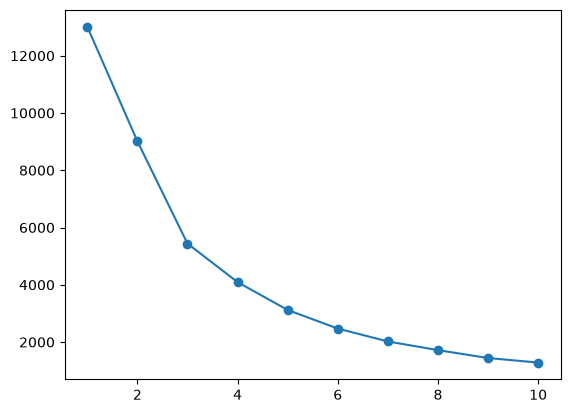

In [129]:
inertias = [] # lista com todas as inércias

for k in range(1, 11): # o limite de clusters será 10
    km = KMeans(n_clusters=k, random_state=0, n_init=10).fit(X_scaled) # criando os clusters 
    inertias.append(km.inertia_) # adicionando a inércia de cada cluster na lista

plt.plot(range(1,11), inertias, 'o-')

A partir do ponto 4 é quando a queda de inércia começa a ficar cada vez menor e constante, significando que esse é o número ideal de clusters.

In [130]:
kmeans = KMeans(n_clusters=4, random_state=0, n_init='auto')
kmeans.fit(X_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",4
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",0
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](4, 3)","[[

#### Clusterização ####

<Axes: xlabel='Recency', ylabel='Frequency'>

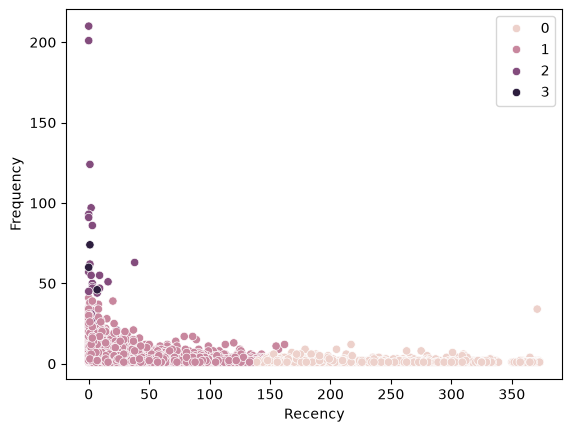

In [131]:
sns.scatterplot(x=rfm['Recency'], y=rfm['Frequency'], hue=kmeans.labels_)

#### Criando o sistema de recomendações ####

Criando a coluna que indica a qual cluster cada cliente pertence.

In [133]:
rfm['Clusters'] = kmeans.labels_

Adicionando a descrição de cada produto comprado por cliente no DataFrame.

In [134]:
rfm = pd.merge(rfm, df[['Description', 'CustomerID']], on="CustomerID")

In [135]:
rfm

,CustomerID,Recency,Frequency,Monetary,Clusters,Description
0,12346.0,325,1,77183.60,0,MEDIUM CERAMIC TOP STORAGE JAR
1,12347.0,1,7,4310.00,1,BLACK CANDELABRA T-LIGHT HOLDER
2,12347.0,1,7,4310.00,1,AIRLINE BAG VINTAGE JET SET BROWN
3,12347.0,1,7,4310.00,1,COLOUR GLASS. STAR T-LIGHT HOLDER
4,12347.0,1,7,4310.00,1,MINI PAINT SET VINTAGE
...,...,...,...,...,...,...
397919,18287.0,42,3,1837.28,1,LIPSTICK PEN RED
397920,18287.0,42,3,1837.28,1,HAND WARMER SCOTTY DOG DESIGN
397921,18287.0,42,3,1837.28,1,SET OF 3 WOODEN SLEIGH DECORATIONS
397922,18287.0,42,3,1837.28,1,PAINTED METAL STAR WITH HOLLY BELLS


#### Passo a passo do processo de recomendação de produto para um cliente ####

1. Escolher um cliente aleatório
2. Ver a qual perfil ele se enquadra
3. Ver todos os produtos comprados por aquele tipo de perfil e ver quais o cliente escolhido ainda não comprou
4. Os produtos que esse cliente ainda não comprou serão os recomendados

##### Escolhendo o cliente #####

In [148]:
cliente = 12347

##### Vendo a qual cluster esse cliente pertence #####

In [149]:
cluster = rfm.loc[rfm['CustomerID'] == cliente, 'Clusters'].iloc[0]

print(f'Cluster: {cluster}') 

Cluster: 1


In [150]:
filtro = rfm['Clusters'] == cluster # escolhendo o valor a ser filtrado

rfm[filtro] # mostrando as linhas que tem o valor que eu quis filtrar

,CustomerID,Recency,Frequency,Monetary,Clusters,Description
1,12347.0,1,7,4310.00,1,BLACK CANDELABRA T-LIGHT HOLDER
2,12347.0,1,7,4310.00,1,AIRLINE BAG VINTAGE JET SET BROWN
3,12347.0,1,7,4310.00,1,COLOUR GLASS. STAR T-LIGHT HOLDER
4,12347.0,1,7,4310.00,1,MINI PAINT SET VINTAGE
5,12347.0,1,7,4310.00,1,CLEAR DRAWER KNOB ACRYLIC EDWARDIAN
...,...,...,...,...,...,...
397919,18287.0,42,3,1837.28,1,LIPSTICK PEN RED
397920,18287.0,42,3,1837.28,1,HAND WARMER SCOTTY DOG DESIGN
397921,18287.0,42,3,1837.28,1,SET OF 3 WOODEN SLEIGH DECORATIONS
397922,18287.0,42,3,1837.28,1,PAINTED METAL STAR WITH HOLLY BELLS


##### Vendo quais produtos o cliente ainda não comprou #####

Vendo todos os produtos comprados pelos clientes do mesmo cluster

In [151]:
filtro1 = rfm['CustomerID'] == cliente # escolhendo o valor a ser filtrado

rfm[filtro1] # mostrando as linhas que tem o valor que eu quis filtrar

,CustomerID,Recency,Frequency,Monetary,Clusters,Description
1,12347.0,1,7,4310.0,1,BLACK CANDELABRA T-LIGHT HOLDER
2,12347.0,1,7,4310.0,1,AIRLINE BAG VINTAGE JET SET BROWN
3,12347.0,1,7,4310.0,1,COLOUR GLASS. STAR T-LIGHT HOLDER
4,12347.0,1,7,4310.0,1,MINI PAINT SET VINTAGE
5,12347.0,1,7,4310.0,1,CLEAR DRAWER KNOB ACRYLIC EDWARDIAN
...,...,...,...,...,...,...
178,12347.0,1,7,4310.0,1,WOODLAND CHARLOTTE BAG
179,12347.0,1,7,4310.0,1,PINK GOOSE FEATHER TREE 60CM
180,12347.0,1,7,4310.0,1,CHRISTMAS TABLE SILVER CANDLE SPIKE
181,12347.0,1,7,4310.0,1,MINI PLAYING CARDS SPACEBOY


Criando dois sets, um com todos os produtos comprados pelos clientes daquele cluster e outro com todos os produtos comprados pelo cliente escolhido.

In [152]:
produtos_cluster = set(rfm['Description'])
produtos_cliente = set(rfm['Description'])

##### Lista dos produtos recomendados #####

In [155]:
recomendacoes = produtos_cluster - produtos_cliente

In [156]:
list(recomendacoes)

[]